**PRACTICA 5**

Integrantes:
   

  
   - Paula García
   - Valentina Morales

   ---

**Parte guiada**

Se parte de la señal analógica $x_a(t) = A\sin(2\pi F_0 t)$ con $F_0 = 40$ Hz y $A = 5$ V, muestreada a $F_s = 1000$ Hz.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Fo = 40            # frecuencia de la señal (Hz)
Tp = 1/Fo          # periodo de la señal: 0.025 s
Fs = 1000          # frecuencia de muestreo (Hz)
T = 1/Fs           # periodo de muestreo: 0.001 s
A = 5              # amplitud (V)

t = np.arange(0, Tp+T, T)        # tiempo de un ciclo (más una muestra)
x = A*np.sin(2*np.pi*Fo*t)       # señal en función del tiempo (s)

fo = Fo/Fs                       # frecuencia discreta: 0.04
n = np.arange(0, len(t))         # índices de muestra: 0, 1, 2, ...
x1 = A*np.sin(2*np.pi*fo*n)      # la misma señal en función de n

a) Compruebe que los valores de las primeras cinco muestras son los mismos

In [2]:
print(x[:5])
print(x1[:5])
print(np.allclose(x, x1))   # True si todas las muestras coinciden

[0.         1.24344944 2.40876837 3.42273553 4.22163963]
[0.         1.24344944 2.40876837 3.42273553 4.22163963]
True


**Respuesta.** Las primeras cinco muestras de $x(t)$ y $x_1(n)$ son iguales (0, 1.2434, 2.4088, 3.4227 y 4.2216 V). Esto pasa porque $t = nT$, entonces $2\pi F_0 t = 2\pi (F_0/F_s) n$. Es la misma señal, solo cambia el eje: segundos en una y número de muestra en la otra.


---

b) La potencia es la misma que en x(n). ¿Por qué?

Se calcula la energía, la potencia media y el valor RMS de un ciclo, y luego de 10 ciclos.

In [3]:
# Un ciclo
energia = sum(x**2)
potencia = energia/(len(t)-1)
rms = np.sqrt(potencia)

# Diez ciclos (250 ms)
t10 = np.arange(0, 10*Tp+T, T)
x10 = A*np.sin(2*np.pi*Fo*t10)
energia10 = sum(x10**2)
potencia10 = energia10/(len(t10)-1)
rms10 = np.sqrt(potencia10)

print("1 ciclo:   E =", energia, " P =", potencia, " RMS =", rms)
print("10 ciclos: E =", energia10, " P =", potencia10, " RMS =", rms10)

1 ciclo:   E = 312.50000000000006  P = 12.500000000000002  RMS = 3.5355339059327378
10 ciclos: E = 3125.0000000000014  P = 12.500000000000005  RMS = 3.535533905932738


**Respuesta.** Con un ciclo la energía es 312.5 V²·s y con 10 ciclos es 3125 V²·s, pero la potencia es 12.5 W en los dos casos (RMS = 3.54 V). La potencia es la energía promediada en el tiempo: con 10 ciclos la energía se multiplica por 10, pero también se divide entre 10 veces más muestras. Como la señal es periódica, cada ciclo aporta lo mismo. El resultado coincide con el valor teórico $A^2/2 = 12.5$ W.

---

**Aplicación**

**1. Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.**

Fs mínima teórica: mayor que 320 Hz
Muestras: 250  Duración: 0.25 s


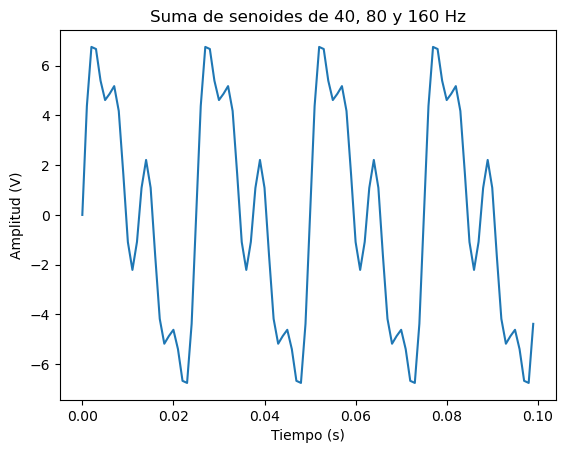

In [4]:
F = [40, 80, 160]      # frecuencias de las componentes (Hz)
A = [5, 3, 2]          # amplitudes (V), distintas para reconocerlas en el espectro

Fmax = max(F)          # frecuencia más alta: 160 Hz
Fs_min = 2*Fmax        # 320 Hz: Fs debe ser MAYOR que este valor (Nyquist)
print("Fs mínima teórica: mayor que", Fs_min, "Hz")

Fs = 1000              # frecuencia de muestreo elegida (Hz)
T = 1/Fs
Tp = 1/40              # periodo de la fundamental (40 Hz)
t = np.arange(0, 10*Tp, T)    # 10 periodos: 0.25 s, 250 muestras

x = sum(a*np.sin(2*np.pi*f*t) for a, f in zip(A, F))   # suma de las tres senoides
print("Muestras:", len(t), " Duración:", len(t)*T, "s")

plt.plot(t[:100], x[:100])     # primeros 0.1 s para ver la forma
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.title("Suma de senoides de 40, 80 y 160 Hz")
plt.show()

**Respuesta.** La componente de mayor frecuencia es de 160 Hz. Por el criterio de Nyquist, la frecuencia de muestreo debe ser mayor que el doble de esa frecuencia: $F_s > 2 \cdot 160 = 320$ Hz. Se usó $F_s = 1000$ Hz, que cumple el criterio y deja unas 6 muestras por ciclo del componente de 160 Hz, suficiente para ver bien la forma de onda. Se tomaron 10 periodos de la fundamental (0.25 s), es decir, 250 muestras.


---

**2. Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).**

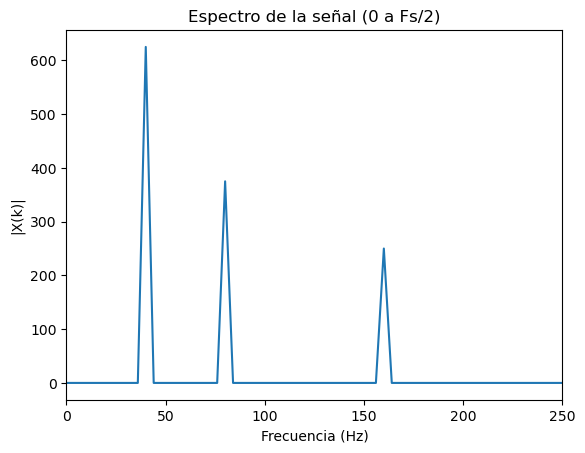

f = 40 Hz | |X| = 625.0 | amplitud = 5.00 V
f = 80 Hz | |X| = 375.0 | amplitud = 3.00 V
f = 160 Hz | |X| = 250.0 | amplitud = 2.00 V


In [5]:
from scipy.signal import find_peaks

X = np.fft.fft(x)                  # DFT de la señal (250 puntos, números complejos)
N = len(X)                         # número de muestras: 250
frec = np.arange(0, N)*Fs/N        # eje de frecuencias: F = k*Fs/N (Hz)

# Solo la primera mitad (hasta Fs/2 = 500 Hz, la frecuencia de Nyquist)
Nmitad = int(np.ceil(N/2))
frec_mitad = frec[:Nmitad]
X_mitad = abs(X[:Nmitad])          # módulo de la DFT

plt.plot(frec_mitad, X_mitad)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|X(k)|")
plt.title("Espectro de la señal (0 a Fs/2)")
plt.xlim(0, 250)                   # zoom para ver los picos
plt.show()

# Identificar los picos automáticamente
picos, _ = find_peaks(X_mitad, height=10)
for k in picos:
    print(f"f = {frec_mitad[k]:.0f} Hz | |X| = {X_mitad[k]:.1f} | amplitud = {2*X_mitad[k]/N:.2f} V")

**Respuesta.** En el espectro aparecen tres picos, en 40, 80 y 160 Hz, que son las frecuencias de las componentes de la señal. La resolución en frecuencia es $F_s/N = 1000/250 = 4$ Hz, por eso cada componente cae justo en un punto de la DFT (k = 10, 20 y 40). Como se usaron 10 periodos completos de la señal, no hay fugas de energía: fuera de esos tres picos el espectro es prácticamente cero. El valor del pico es $|X(k)| = N \cdot A/2$, entonces la amplitud se recupera con $A = 2|X(k)|/N$ (5, 3 y 2 V), que coincide con las amplitudes usadas. Solo se grafica hasta $F_s/2 = 500$ Hz porque la otra mitad es simétrica (la señal es real).


---

**3. Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior.**

La función de NumPy para calcular la transformada discreta inversa de Fourier es `np.fft.ifft`. Calcula

$$x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\, e^{j 2\pi k n / N}$$

es decir, recupera la señal en el tiempo a partir de su DFT (Proakis y Manolakis, 2007).

complex128
1.8731968869366787e-15
3.552713678800501e-15
True


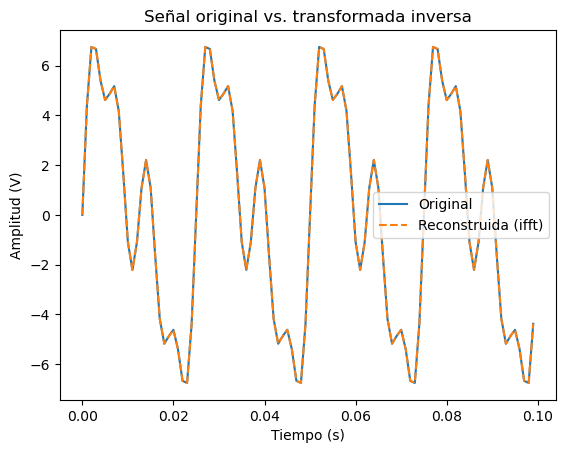

In [6]:
xr = np.fft.ifft(X)       # transformada inversa de la DFT X calculada en el punto 2

print(xr.dtype)                          # complex128: el resultado viene como complejo
print(abs(xr.imag).max())                # parte imaginaria: casi cero (~1e-15)
print(abs(x - xr.real).max())            # error máximo contra la señal original
print(np.allclose(x, xr.real))           # True: la señal se recuperó

plt.plot(t[:100], x[:100], label="Original")
plt.plot(t[:100], xr.real[:100], "--", label="Reconstruida (ifft)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.title("Señal original vs. transformada inversa")
plt.legend()
plt.show()

**Respuesta.** Al aplicar `np.fft.ifft` a la DFT de la señal se obtiene de vuelta la señal original. El resultado de la función es complejo, pero su parte imaginaria es prácticamente cero (del orden de $10^{-15}$, error numérico del computador), por lo que se toma la parte real con `.real`. El error máximo entre la señal original y la reconstruida es de $3.6 \times 10^{-15}$ V, lo que confirma que la DFT y su inversa son un par de transformadas sin pérdida de información.

---

**4. ¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?**



C:\Users\Valentina Morales\AppData\Local\Temp\ipykernel_4340\77351545.py:3: ComplexWarning: Casting complex values to real discards the imaginary part
  F2[9:13] = F1[9:13]


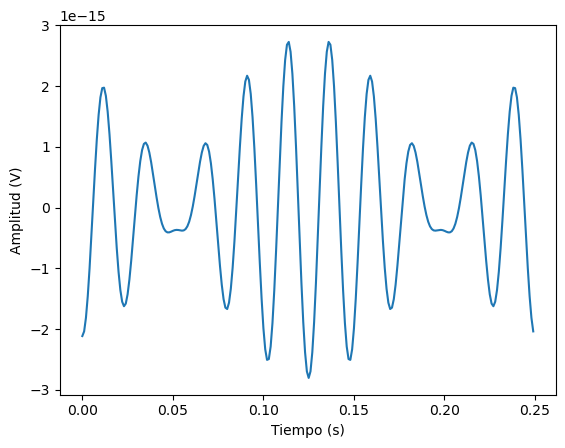

float64 2.8056149108778773e-15


In [ ]:
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)))
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)')
plt.show()

print(F2.dtype, abs(np.real(xr)).max())

**Respuesta.** Sí, las líneas aplican un filtro, pero en el dominio de la frecuencia. Lo que hace cada línea es:

- `F1 = np.fft.fft(x)`: calcula la DFT de la señal, o sea, su espectro.
- `F2 = np.zeros(len(F1))`: crea un espectro vacío, con todos los valores en cero.
- `F2[9:13] = F1[9:13]`: copia solo los coeficientes de los índices 9 a 12 y deja todos los demás en cero. Con $N = 250$ y $F_s = 1000$ Hz, cada índice equivale a $kF_s/N = 4k$ Hz, por lo que esos índices corresponden a 36, 40, 44 y 48 Hz.
- `xr = np.fft.ifft(F2)`: pasa de nuevo al tiempo con el espectro recortado.

Es un filtro porque deja pasar unas frecuencias (las cercanas a 40 Hz) y elimina las demás (en este caso, los componentes de 80 y 160 Hz). Más exactamente es un filtro pasa-banda ideal, ya que corta de forma abrupta, sin zona de transición.

--- 

**Extraiga de manera similar cada una de las componentes de la señal.**

Para que el filtro funcione, el arreglo debe ser complejo (`dtype=complex`). Se repite el procedimiento conservando los mismos índices (9 a 12):

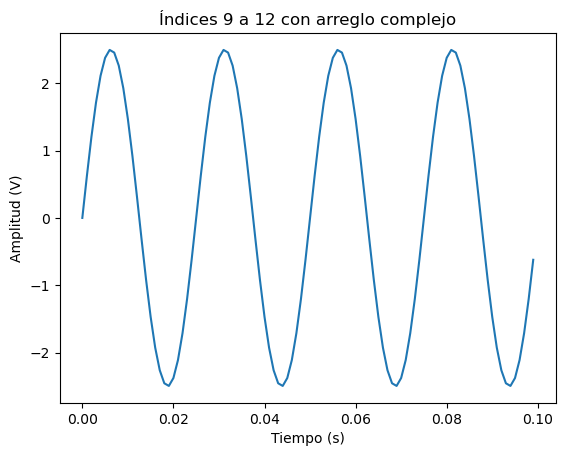

2.4950668210706817


In [9]:
F2c = np.zeros(len(F1), dtype=complex)    # arreglo complejo, ahora no se pierde la parte imaginaria
F2c[9:13] = F1[9:13]
xr_c = np.fft.ifft(F2c)

plt.plot(t[:100], np.real(xr_c[:100]))
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.title("Índices 9 a 12 con arreglo complejo")
plt.show()
print(abs(np.real(xr_c)).max())           # ≈ 2.5

Con el arreglo complejo se obtiene una senoide de 40 Hz, pero con amplitud de 2.5 V en lugar de 5 V. Esto ocurre porque el espectro de una señal real es simétrico: la mitad de la amplitud está en la frecuencia positiva (índice $k$) y la otra mitad en su simétrica negativa (índice $N-k$). El código solo conserva el lado positivo, por lo que se recupera la mitad de la señal.

40 Hz | k = 10 | error máx = 2.9000972272962627e-14
80 Hz | k = 20 | error máx = 3.5074015138087033e-14
160 Hz | k = 40 | error máx = 5.2735593669694936e-14


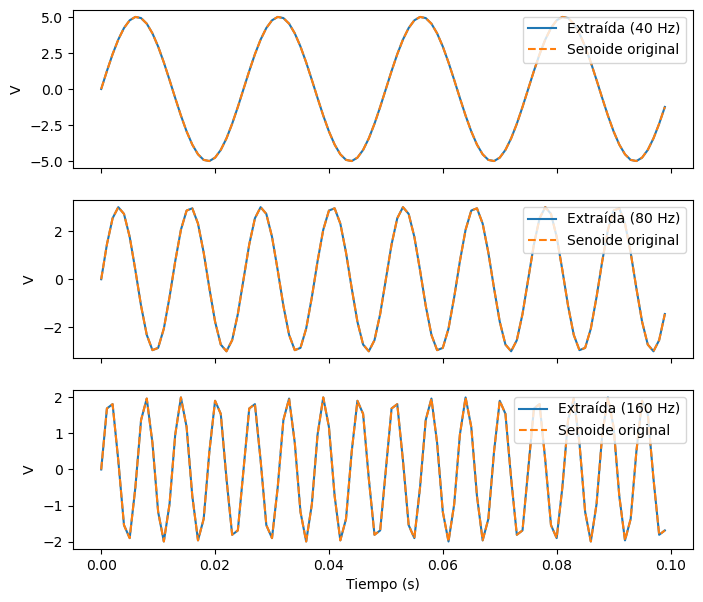

In [10]:
def extraer_componente(F1, k):
    # Deja solo el índice k y su simétrico N-k; el resto se pone en cero
    N = len(F1)
    G = np.zeros(N, dtype=complex)
    G[k] = F1[k]
    G[N-k] = F1[N-k]
    return np.real(np.fft.ifft(G))

N = len(x)
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for a, f, amp in zip(ax, [40, 80, 160], [5, 3, 2]):
    k = int(round(f*N/Fs))                     # índice de cada frecuencia: 10, 20 y 40
    comp = extraer_componente(F1, k)
    a.plot(t[:100], comp[:100], label=f"Extraída ({f} Hz)")
    a.plot(t[:100], amp*np.sin(2*np.pi*f*t[:100]), "--", label="Senoide original")
    a.set_ylabel("V")
    a.legend(loc="upper right")
    print(f, "Hz | k =", k, "| error máx =", abs(comp - amp*np.sin(2*np.pi*f*t)).max())
ax[-1].set_xlabel("Tiempo (s)")
plt.show()

Para extraer cada componente se conserva únicamente su coeficiente $k = fN/F_s$ (10, 20 y 40 para 40, 80 y 160 Hz) junto con su simétrico $N-k$, y se aplica la transformada inversa. Con esto se recuperan las tres senoides originales, de 5, 3 y 2 V, con un error del orden de $10^{-14}$ V. Al sumar las tres componentes se reconstruye la señal original.

---

**5. Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales construidas anteriormente.**

**Algoritmo.** El periodograma de Welch estima la densidad espectral de potencia (PSD) de una señal promediando varios periodogramas calculados en segmentos que se solapan:

1. Se divide la señal de $N$ muestras en $K$ segmentos de longitud $L$ (`nperseg`), con un solapamiento de `noverlap` muestras. El paso entre segmentos es $L - \text{noverlap}$ y $K = \lfloor (N - \text{noverlap}) / (L - \text{noverlap}) \rfloor$.
2. A cada segmento se le resta su media.
3. Se multiplica por una ventana $w(n)$ (aquí Hanning, $w(n) = 0.5 - 0.5\cos(2\pi n / L)$), para reducir la fuga espectral que causan los cortes abruptos en los bordes del segmento.
4. Se calcula la DFT de cada segmento con la FFT, y el periodograma modificado $P(k) = \dfrac{|X(k)|^2}{F_s \, U}$, con $U = \sum w^2(n)$. Dividir entre $U$ compensa la energía que quita la ventana.
5. Como la señal es real, el espectro es simétrico; se conserva solo de 0 a $F_s/2$ y se duplica el valor de las frecuencias intermedias para conservar la potencia total.
6. Se promedian los $K$ periodogramas. El resultado es la PSD en $V^2/\text{Hz}$, con frecuencias $f_k = kF_s/L$.

Promediar reduce la varianza del estimador, a costa de perder resolución en frecuencia ($F_s/L$ en lugar de $F_s/N$).

In [12]:
def welch_manual(x, fs, nperseg, noverlap):
    x = np.asarray(x, dtype=float)
    N = len(x)
    paso = nperseg - noverlap                 # cuánto avanza cada segmento
    K = (N - noverlap)//paso                  # número de segmentos completos

    n = np.arange(nperseg)
    w = 0.5 - 0.5*np.cos(2*np.pi*n/nperseg)   # ventana Hanning
    U = np.sum(w**2)                          # energía de la ventana

    psd = np.zeros(nperseg//2 + 1)            # aquí se acumula la suma de periodogramas
    for i in range(K):
        seg = x[i*paso : i*paso + nperseg]    # 1. cortar el segmento i
        seg = seg - np.mean(seg)              # 2. restar la media
        seg = seg*w                           # 3. aplicar la ventana
        Xk = np.fft.fft(seg)                  # 4. DFT del segmento
        P = (np.abs(Xk)**2)/(fs*U)            #    periodograma modificado
        P = P[:nperseg//2 + 1]                # 5. solo de 0 a Fs/2
        if nperseg % 2 == 0:
            P[1:-1] = 2*P[1:-1]               #    duplicar (sin DC ni Nyquist)
        else:
            P[1:] = 2*P[1:]                   #    duplicar (sin DC)
        psd += P

    psd /= K                                  # 6. promedio de los K periodogramas
    f = np.arange(nperseg//2 + 1)*fs/nperseg  # eje de frecuencias (Hz)
    return f, psd

Máxima diferencia relativa: 5.329070518200747e-16


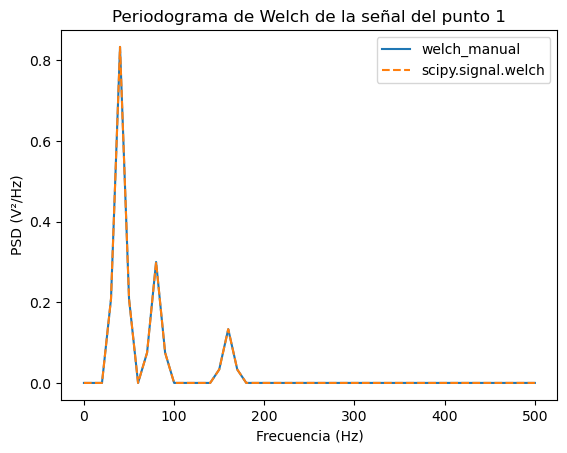

In [13]:
from scipy.signal import welch

L = 100          # largo de cada segmento (resolución Fs/L = 10 Hz)
ov = 50          # solapamiento de 50 %
f_m, psd_m = welch_manual(x, Fs, L, ov)
f_s, psd_s = welch(x, Fs, window="hann", nperseg=L, noverlap=ov, detrend="constant")

print("Máxima diferencia relativa:", np.max(np.abs(psd_m - psd_s))/psd_s.max())

plt.plot(f_m, psd_m, label="welch_manual")
plt.plot(f_s, psd_s, "--", label="scipy.signal.welch")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD (V²/Hz)")
plt.title("Periodograma de Welch de la señal del punto 1")
plt.legend()
plt.show()

**Resultados.** Se probó la función con la señal del punto 1 ($F_s = 1000$ Hz, $N = 250$), usando segmentos de $L = 100$ muestras y 50 % de solapamiento ($K = 4$ segmentos). El periodograma muestra picos en 40, 80 y 160 Hz, con la mayor potencia en 40 Hz, que es la componente de mayor amplitud (5 V). La función creada coincide con `scipy.signal.welch` (diferencia relativa del orden de $10^{-16}$), lo que valida la implementación. Alrededor de cada pico aparecen valores en las frecuencias vecinas (por ejemplo, 30 y 50 Hz): es el efecto de la ventana Hanning, que ensancha los picos.